# code_129 · Boundary constructions and conservative learned fluxes

**Book:** section 25.3. A self-contained scientific-learning laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_25_GUIDE.md), [run evidence](../CHAPTER_25_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_129).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2929;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2929


<a id="constraint-contracts"></a>
 ## Exact endpoint values are a narrower claim than an exact solution
 A normalized axial displacement satisfies −u''=pi² sin(pi*x), with zero endpoints and truth sin(pi*x). Fit identical two-layer sixteen-unit tanh networks with either a soft endpoint penalty or the hard construction u=x(1−x)N(x). Both receive 32 source collocation locations, 1,000 Adam updates at0.005 and the same initialization; the soft weight is fixed at10. No dense truth is used for fitting or selecting a winner. Assess on a separate 401-point grid. A second experiment learns thirteen positive edge conductances of a twelve-interior-node finite-volume chain from eight source load/response cases. Exact discrete flux assembly cancels internal exchanges for every parameter value. Two development and two final loads are separate cases, though they share this known physical domain and conductance field.


,model,final_field_MSE,final_scaled_residual_MSE,max_endpoint_displacement,trainable_parameters
0,Soft endpoint penalty,1.372704e-07,0.000056,0.000023,321
1,Hard endpoint construction,6.173495e-09,0.000007,0.000000,321


Conservative learned-solve evidence: {'conductance_MSE': 0.0003584783326194274, 'minimum_conductance': 0.7109369099888891, 'source_response_MSE': 2.4737379936993086e-09, 'development_response_MSE': 9.49389811707473e-10, 'final_response_MSE': 2.831167492048755e-10, 'max_interior_equilibrium_error': 8.881784197001252e-15, 'max_global_flux_balance_error': 5.551115123125783e-16, 'case_counts': [8, 2, 2], 'edge_parameters': 13}


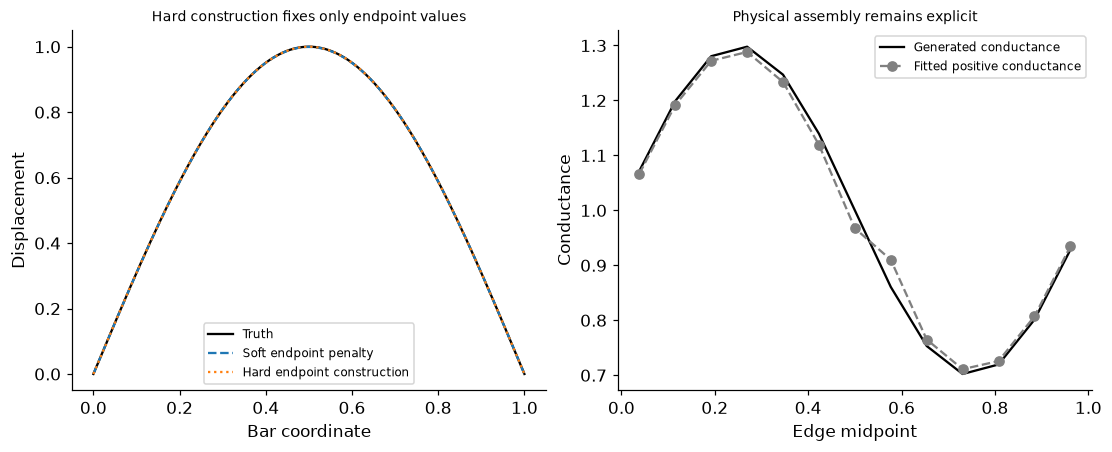

In [2]:
def deriv(y,x,order=1):
    for j in range(order):y=torch.autograd.grad(y,x,torch.ones_like(y),create_graph=True)[0]
    return y
def make():return nn.Sequential(nn.Linear(1,16),nn.Tanh(),nn.Linear(16,16),nn.Tanh(),nn.Linear(16,1))
xc=torch.linspace(.015,.985,32)[:,None].requires_grad_(True);xb=torch.tensor([[0.],[1.]]);xt=torch.linspace(0,1,401)[:,None].requires_grad_(True);models={};rows=[]
for name,hard in [('Soft endpoint penalty',False),('Hard endpoint construction',True)]:
    torch.manual_seed(SEED);net=make();opt=torch.optim.Adam(net.parameters(),lr=.005)
    def output(x):return x*(1-x)*net(x) if hard else net(x)
    for step in range(1000):
        opt.zero_grad();u=output(xc);r=-deriv(u,xc,2)-torch.pi**2*torch.sin(torch.pi*xc);loss=(r/torch.pi**2).square().mean()+10*output(xb).square().mean();loss.backward();opt.step()
    u=output(xt);r=-deriv(u,xt,2)-torch.pi**2*torch.sin(torch.pi*xt);rows.append({'model':name,'final_field_MSE':float((u-torch.sin(torch.pi*xt)).square().mean().detach()),'final_scaled_residual_MSE':float((r/torch.pi**2).square().mean().detach()),'max_endpoint_displacement':float(output(xb).abs().max().detach()),'trainable_parameters':sum(p.numel() for p in net.parameters())});models[name]=(net,hard)
assert rows[1]['max_endpoint_displacement']==0
N=12;h=1/(N+1);edge_x=(np.arange(N+1)+.5)*h;true_k=torch.tensor(1+.3*np.sin(2*np.pi*edge_x));D=torch.zeros(N+1,N)
for i in range(N):D[i,i]+=1;D[i+1,i]-=1
def matrix(k):return D.T@torch.diag(k)@D/h**2
load_x=torch.tensor(np.arange(1,N+1)*h);loads=torch.stack([torch.sin(torch.pi*load_x)+.4*torch.cos((j+1)*torch.pi*load_x)+.15*torch.tensor(rng.normal(size=N)) for j in range(12)]).T;reference=torch.linalg.solve(matrix(true_k),loads);logk=nn.Parameter(torch.zeros(N+1));opt=torch.optim.Adam([logk],lr=.03)
for step in range(1500):
    opt.zero_grad();k=torch.nn.functional.softplus(logk)+1e-4;u=torch.linalg.solve(matrix(k),loads[:,:8]);loss=(u-reference[:,:8]).square().mean();loss.backward();opt.step()
k=torch.nn.functional.softplus(logk)+1e-4;prediction=torch.linalg.solve(matrix(k),loads);gradients=D@prediction/h;flux=-k[:,None]*gradients;balance=matrix(k)@prediction-loads;global_balance=flux[-1]-flux[0]-h*loads.sum(0);assert float(k.min().detach())>0
torch.testing.assert_close(balance,torch.zeros_like(balance),atol=1e-12,rtol=0);torch.testing.assert_close(global_balance,torch.zeros_like(global_balance),atol=1e-12,rtol=0)
# A direct source-update gradient also differentiates the assembled solve.
assert logk.grad is not None and torch.isfinite(logk.grad).all()
RESULTS.update(boundary_comparisons=rows,conductance_MSE=float((k-true_k).square().mean().detach()),minimum_conductance=float(k.min().detach()),source_response_MSE=float((prediction[:,:8]-reference[:,:8]).square().mean().detach()),development_response_MSE=float((prediction[:,8:10]-reference[:,8:10]).square().mean().detach()),final_response_MSE=float((prediction[:,10:]-reference[:,10:]).square().mean().detach()),max_interior_equilibrium_error=float(balance.abs().max().detach()),max_global_flux_balance_error=float(global_balance.abs().max().detach()),case_counts=[8,2,2],edge_parameters=N+1);display(pd.DataFrame(rows));print('Conservative learned-solve evidence:',{k:v for k,v in RESULTS.items() if k!='boundary_comparisons'})
fig,axes=plt.subplots(1,2,figsize=(10,4));xx=xt.detach().numpy().ravel();axes[0].plot(xx,np.sin(np.pi*xx),'k-',label='Truth')
for (name,(net,hard)),style in zip(models.items(),['--',':']):
    p=xt*(1-xt)*net(xt) if hard else net(xt);axes[0].plot(xx,p.detach().numpy().ravel(),style,label=name)
axes[0].set(xlabel='Bar coordinate',ylabel='Displacement',title='Hard construction fixes only endpoint values');axes[0].legend(fontsize=8);axes[1].plot(edge_x,true_k,'k-',label='Generated conductance');axes[1].plot(edge_x,k.detach().numpy(),'o--',color='.5',label='Fitted positive conductance');axes[1].set(xlabel='Edge midpoint',ylabel='Conductance',title='Physical assembly remains explicit');axes[1].legend(fontsize=8);plt.show()


<a id="conservation-versus-accuracy"></a>
 ## Cancellation follows from shared edge fluxes
 The same edge flux enters adjacent cells with opposite signs. Consequently the interior solve balances its prescribed load to rounding precision even when fitted conductances are inaccurate. Boundary flux difference equals integrated load. Positivity makes the Dirichlet stiffness matrix positive definite; conservation follows from incidence/flux assembly, not positivity alone. The learned field is fitted on one known domain with exact noiseless generated response labels. It does not demonstrate material recovery from sparse field measurements. The hard neural endpoint construction fixes neither differential residuals nor general natural boundary conditions. A different geometry needs a valid boundary extension, and an incompatible hard constraint can exclude the true response entirely.


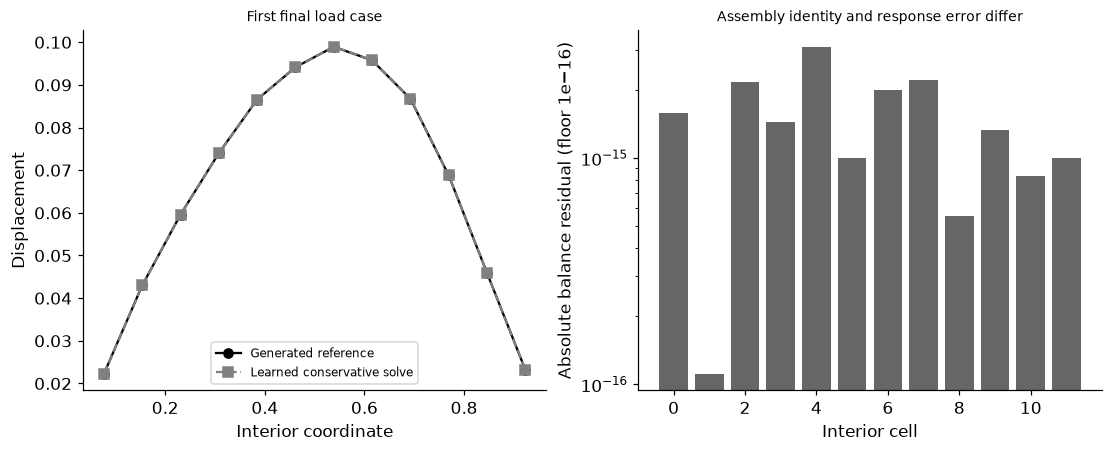

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));j=10;axes[0].plot(load_x,reference[:,j],'ko-',label='Generated reference');axes[0].plot(load_x,prediction[:,j].detach(),'s--',color='.5',label='Learned conservative solve');axes[0].set(xlabel='Interior coordinate',ylabel='Displacement',title='First final load case');axes[0].legend(fontsize=8);axes[1].bar(np.arange(N),np.maximum(np.abs(balance[:,j].detach().numpy()),1e-16),color='.4');axes[1].set(yscale='log',xlabel='Interior cell',ylabel='Absolute balance residual (floor 1e−16)',title='Assembly identity and response error differ');plt.show()
assert len(rows)==2 and torch.linalg.eigvalsh(matrix(k)).min()>0


In [4]:
summary={'example_id':'code_129','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual soft versus hard displacement boundary fits', 'independent differential residual checks', 'learned positive edge conductances', 'differentiable conservative finite-volume solve', 'boundary flux and interior balance identities'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual soft versus hard displacement boundary fits", "independent differential residual checks", "learned positive edge conductances", "differentiable conservative finite-volume solve", "boundary flux and interior balance identities"], "elapsed_seconds": 1.782, "example_id": "code_129", "hardware": "Darwin arm64 CPU", "results": {"boundary_comparisons": [{"final_field_MSE": 1.3727039236951646e-07, "final_scaled_residual_MSE": 5.5992621323308926e-05, "max_endpoint_displacement": 2.2766975778856172e-05, "model": "Soft endpoint penalty", "trainable_parameters": 321}, {"final_field_MSE": 6.1734954877277475e-09, "final_scaled_residual_MSE": 6.5556354391933775e-06, "max_endpoint_displacement": 0.0, "model": "Hard endpoint construction", "trainable_parameters": 321}], "case_counts": [8, 2, 2], "conductance_MSE": 0.0003584783326194274, "development_response_MSE": 9.49389811707473e-10, "edge_parameters": 13, "final_response_MSE": 2.831167492048